In [2]:
import os
import torch
import torchvision
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset, ConcatDataset
from networks import *

import matplotlib.pyplot as plt
import numpy as np

KeyboardInterrupt: 

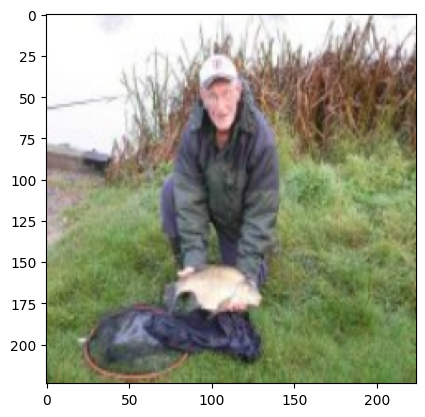

In [26]:

# Data directory: data/imagenet100
# In train.X1 - train.X5 directories, each folder contains 20 classes folder and each class folder contains images
# val.X directory contains 100 classes folder and each class folder contains images
# get label from Labels.json key sequence


def load_data(data_dir, batch_size=32, num_workers=4):
    # Define transforms
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        # transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])

        
    train_datasets = []
    for i in range(1, 5):
        train_dir = os.path.join(data_dir, f'train.X{i}')
        train_dataset = datasets.ImageFolder(train_dir, transform=transform)
        train_datasets.append(train_dataset)

    val_dir = os.path.join(data_dir, 'val.X')
    val_dataset = datasets.ImageFolder(val_dir, transform=transform)
    # Combine classes from train datasets into val dataset

    for ds in train_datasets:
        ds.class_to_idx = val_dataset.class_to_idx
        ds.samples = [(path, ds.class_to_idx[path.split('/')[-2]]) for path, idx in ds.samples]

    # Combine train datasets
    train_dataset = ConcatDataset(train_datasets)

    # Create data loaders
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=num_workers)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers)

    return train_dataset, val_dataset, train_loader, val_loader

# Example usage
data_dir = 'data/imagenet100'
train_dataset, val_dataset, train_loader, val_loader = load_data(data_dir)

for idx in [0,10,20]:
    for image, label in train_loader:
        if label[0] != idx:
            continue
        plt.imshow(image[0].permute(1, 2, 0))

for idx in [0,10,20]:
    for image, label in val_loader:
        if label[0] != idx:
            continue
        plt.imshow(image[0].permute(1, 2, 0))
    